# Midterm Project: Who Will Leave the Bank? Predicting Customer Churn

**Names:** Sarvar (240091), Nazarbek (240311) · **Dataset:** [Bank Customer Churn Prediction (Kaggle, Shantanu Dhakad)](https://www.kaggle.com/datasets/shantanudhakadd/bank-customer-churn-prediction) · **Task:** binary classification

## 1. The question

**What am I predicting?** Whether a bank customer will **leave the bank** (`Exited = 1`) or **stay** (`Exited = 0`), using information the bank already has about them: credit score, country, gender, age, years with the bank, balance, number of products, credit card, activity and salary.

**Why is it interesting?** Keeping an existing customer is much cheaper than finding a new one. If the bank can spot *in advance* who is likely to leave, it can call them or offer something to make them stay.

**Type of problem:** this is **classification** (binary): the answer is a category (*leaves / stays*), not a number.

**What matters most:** missing a customer who is about to leave (a *false negative*) costs the bank more than calling a happy customer by mistake (a *false positive*). So besides accuracy we will pay special attention to **recall** for the "leaves" class.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so the results are the same on every run

## 2. Explore the data (EDA)

### 2.1 First look

In [ ]:
import os

# Works locally and in Google Colab: if the CSV is not next to the notebook, Colab asks you to upload it.
if not os.path.exists("Churn_Modelling.csv"):
    try:
        from google.colab import files
        print("Please upload Churn_Modelling.csv (download it from the Kaggle link at the top).")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put Churn_Modelling.csv in the same folder as this notebook.")

df = pd.read_csv("Churn_Modelling.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [ ]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5000.5,2886.9,1.0,2500.8,5000.5,7500.2,10000.0
CustomerId,10000.0,15690940.6,71936.2,15565701.0,15628528.2,15690738.0,15753233.8,15815690.0
CreditScore,10000.0,650.5,96.7,350.0,584.0,652.0,718.0,850.0
Age,10000.0,38.9,10.5,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,5.0,2.9,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,76485.9,62397.4,0.0,0.0,97198.5,127644.2,250898.1
NumOfProducts,10000.0,1.5,0.6,1.0,1.0,1.0,2.0,4.0
HasCrCard,10000.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
IsActiveMember,10000.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0
EstimatedSalary,10000.0,100090.2,57510.5,11.6,51002.1,100193.9,149388.2,199992.5


### 2.2 Missing values and duplicates

In [ ]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:        ", df.duplicated().sum())
print("Duplicate customer IDs:", df["CustomerId"].duplicated().sum())

Missing values per column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate rows:         0
Duplicate customer IDs: 0


### 2.3 The target: how many customers left?

In [ ]:
print(df["Exited"].value_counts())
print()
print((df["Exited"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

Exited
0    7963
1    2037
Name: count, dtype: int64

Exited
0    79.6 %
1    20.4 %
Name: proportion, dtype: str


**First observations**

- 10,000 customers × 14 columns. **No missing values and no duplicates**, so there is nothing to fill in or remove.
- `RowNumber`, `CustomerId` and `Surname` are just identifiers. They say nothing about a customer's behaviour, so we will **not** use them as features.
- Only **~20 %** of customers left. The classes are **imbalanced**: a "model" that always answers *stays* would already get ~80 % accuracy while catching zero leavers. That is why accuracy alone is not enough here.
- The Kaggle description says "U.S. bank", but the `Geography` column only contains **France, Germany and Spain**, so the description is not accurate. We trust the data itself.

### 2.4 Distributions of the numeric columns

A histogram shows *how many* customers fall into each range of values. We skip the ID columns and the target.

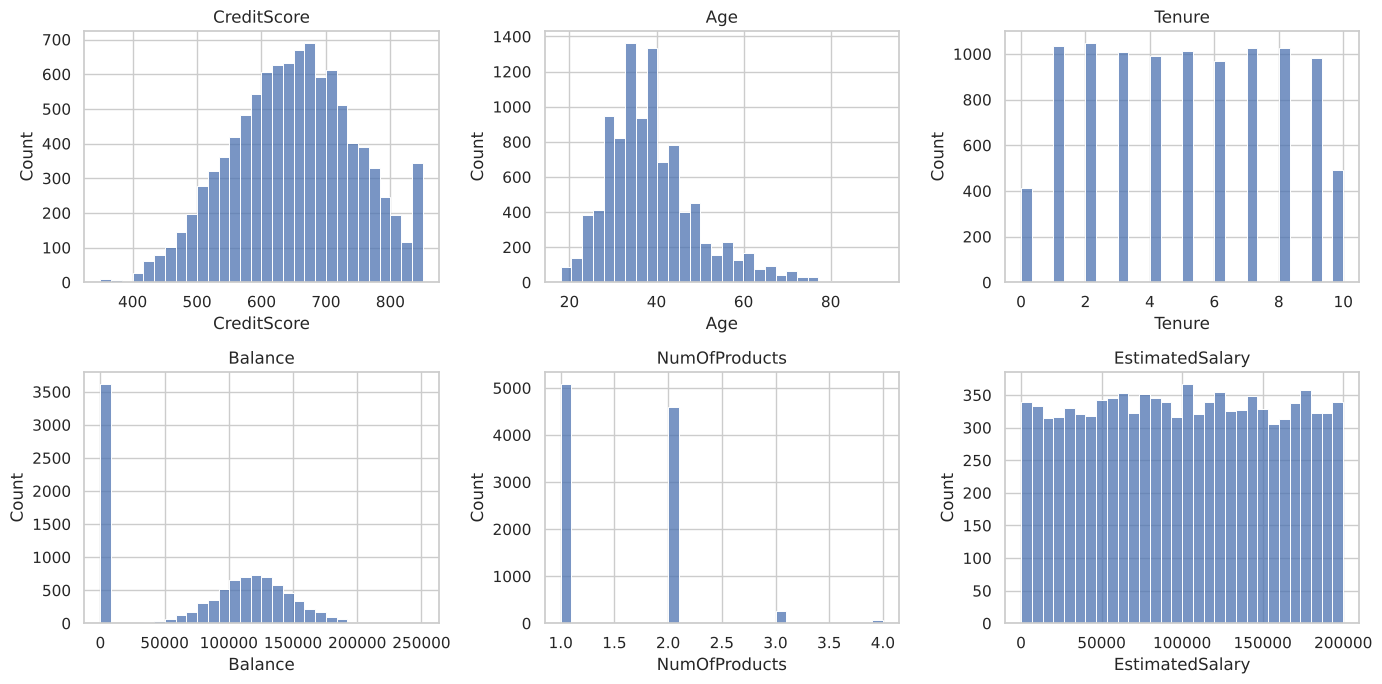

In [ ]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.5 Outliers

A boxplot shows the "typical" range as a box; dots far outside the box are **outliers** (values unusually far from the rest).

CreditScore: 15 outliers
Age: 359 outliers


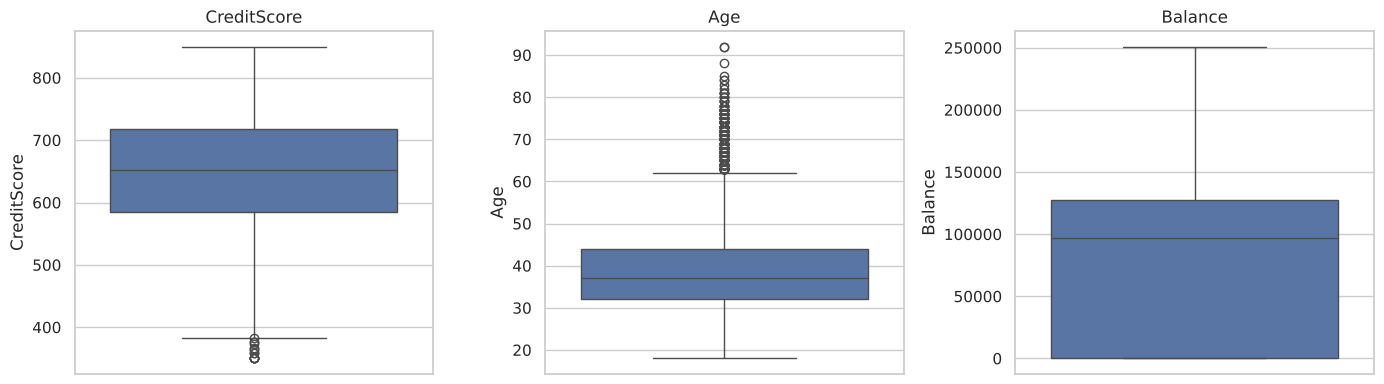

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["CreditScore", "Age", "Balance"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# how many outliers does the 1.5 x IQR rule find?
for col in ["CreditScore", "Age"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n} outliers")

### 2.6 Who leaves? Churn rate by group

For each group we compute the **share of customers who left** (the mean of `Exited`). The dashed line is the overall churn rate (~20 %).

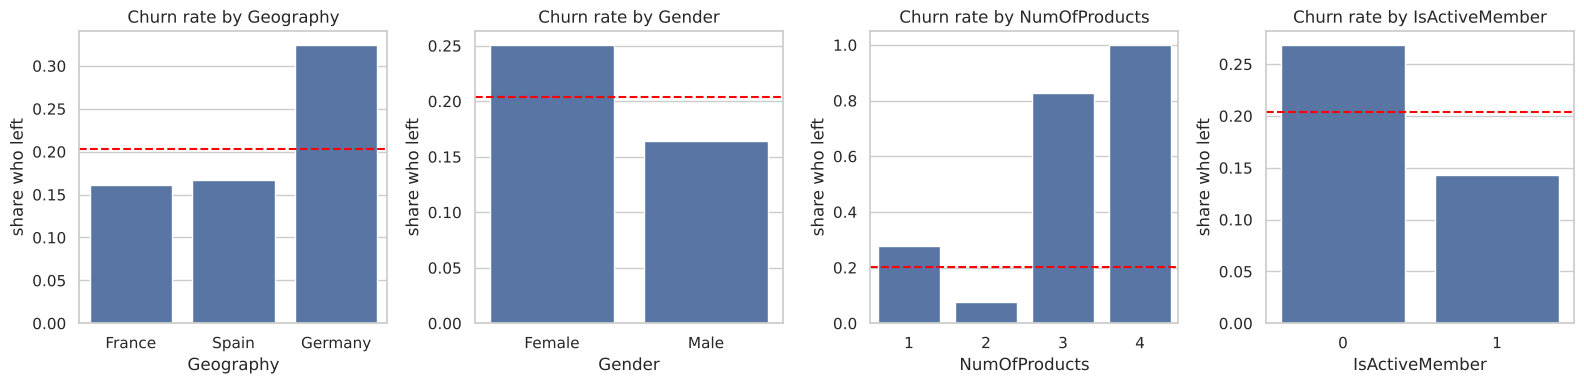

In [ ]:
cat_cols = ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]
overall = df["Exited"].mean()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    sns.barplot(x=col, y="Exited", data=df, errorbar=None, ax=ax)
    ax.axhline(overall, color="red", linestyle="--")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("share who left")
plt.tight_layout()
plt.show()

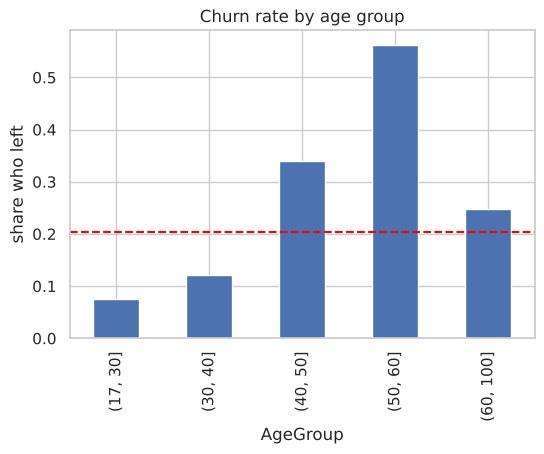

In [ ]:
# Churn rate by age group
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100])
age_churn = df.groupby("AgeGroup", observed=True)["Exited"].mean()
age_churn.plot(kind="bar", figsize=(6, 4), title="Churn rate by age group")
plt.axhline(overall, color="red", linestyle="--")
plt.ylabel("share who left")
plt.show()

df = df.drop(columns="AgeGroup")  # helper column only for this chart; keep df clean

In [ ]:
# Customers with zero balance
print("Share of customers with Balance = 0:", round((df["Balance"] == 0).mean() * 100, 1), "%")
print(df.groupby("Geography")["Balance"].apply(lambda s: round((s == 0).mean() * 100, 1)).rename("% with zero balance"))

Share of customers with Balance = 0: 36.2 %
Geography
France     48.2
Germany     0.0
Spain      48.4
Name: % with zero balance, dtype: float64


### 2.7 What I notice (summary of the EDA)

1. **The data is clean but imbalanced.** No missing values or duplicates, but only ~20 % of customers left. We must judge the model with recall and F1, not accuracy alone.
2. **Age is a strong signal.** Churn is ~8 % for customers under 30 and climbs above 50 % for customers aged 50-60. `Age` also has ~359 outliers (older customers), but they are real people, not errors, so we keep them.
3. **Product count and activity matter, in a non-obvious way.** Customers with 3-4 products leave far more often (83 % and 100 %), while those with 2 products almost never leave (~8 %). Inactive members and customers in Germany (32 % vs ~16 %) also leave more. Women leave more than men (25 % vs 17 %).
4. **Odd detail:** 36 % of customers have `Balance = 0`, and *none* of them are in Germany. Roughly half of French and Spanish customers have zero balance. This looks like a property of how the data was collected, so we will mention it as a limitation.

Not all relationships are straight lines (e.g. product count), which is a good reason to also try a non-linear model later.

## 3. Prepare the data

**The golden rule:** split first, then fit every preparation step on the **training data only**. The test set must stay untouched until the final evaluation, like an exam whose questions we have not seen while studying.

### 3.1 Choose features and target

- **Target (`y`)**: `Exited`.
- **Features (`X`)**: everything except the target and the three identifier columns (`RowNumber`, `CustomerId`, `Surname`), which describe *who* the customer is, not *how they behave*.
- No column is a disguised version of the answer (no data leakage through features): every column is known *before* the customer decides to leave.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

print("Features:", list(X.columns))
X.head()

Features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


### 3.2 Split into train and test (FIRST step)

- `test_size=0.2`: 80 % of customers to learn from, 20 % held back for the final exam.
- `stratify=y`: keeps the share of leavers (~20 %) the same in both parts. Without it, a random split could put too few leavers in the test set.
- `random_state`: makes the split identical on every run.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "  Test:", X_test.shape)
print("Share of leavers in train:", round(y_train.mean() * 100, 1), "%")
print("Share of leavers in test: ", round(y_test.mean() * 100, 1), "%")

Train: (8000, 10)   Test: (2000, 10)
Share of leavers in train: 20.4 %
Share of leavers in test:  20.3 %


### 3.3 Build the preparation pipeline

Models only understand numbers on a comparable scale, so we treat each type of column differently:

| Columns | What we do | Why |
|---|---|---|
| `CreditScore, Age, Tenure, Balance, NumOfProducts, EstimatedSalary` | fill gaps with the median (safety net) → **StandardScaler** | puts all numbers on the same scale (mean 0, spread 1), so `Balance` (up to 250 000) does not drown out `Tenure` (up to 10) |
| `Geography, Gender` | **OneHotEncoder** | turns text into 0/1 columns, e.g. `Geography_Germany` = 1 if the customer is in Germany |
| `HasCrCard, IsActiveMember` | leave as they are | already 0/1 |

A `ColumnTransformer` applies the right treatment to each group. Later we put it **together with the model inside a `Pipeline`**: when we call `.fit` on the training data, the scaler and encoder learn their numbers (means, categories) from the training data only, and then simply *reuse* them on the test data. This is what prevents leakage.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender"]
bin_cols = ["HasCrCard", "IsActiveMember"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['CreditScore', 'Age', 'Tenure', 'Balance',
                                  'NumOfProducts', 'EstimatedSalary']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Geography', 'Gender']),
                                ('bin', 'passthrough',
                                 ['HasCrCard', 'IsActiveMember'])])

### 3.4 Peek at what the pipeline produces

Here we fit the preprocessor **on the training data only** just to look at the result. (In the next section the model pipeline will do this step automatically.)

In [ ]:
preprocessor.fit(X_train)
X_train_prepared = preprocessor.transform(X_train)

prepared_df = pd.DataFrame(X_train_prepared, columns=preprocessor.get_feature_names_out())
print("Shape after preparation:", prepared_df.shape)
prepared_df.head().round(2)

Shape after preparation: (8000, 13)


,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__EstimatedSalary,cat__Geography_France,cat__Geography_Germany,cat__Geography_Spain,cat__Gender_Female,cat__Gender_Male,bin__HasCrCard,bin__IsActiveMember
0,1.06,1.72,0.68,-1.23,-0.91,1.04,1.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.91,-0.66,-0.70,0.41,-0.91,-0.62,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,1.08,-0.18,-1.73,0.60,0.81,0.31,0.0,1.0,0.0,1.0,0.0,1.0,1.0
3,-0.93,-0.18,-0.01,-1.23,0.81,-0.29,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,0.43,0.96,0.34,0.55,0.81,0.14,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [ ]:
# Proof there is no leakage: the scaler learned its numbers from TRAIN only
scaler = preprocessor.named_transformers_["num"].named_steps["scale"]
print("Mean learned from train:", dict(zip(num_cols, scaler.mean_.round(1))))

X_test_prepared = preprocessor.transform(X_test)   # transform only, no fit
age_idx = num_cols.index("Age")
print("\nTrain mean (scaled Age):", round(X_train_prepared[:, age_idx].mean(), 3))
print("Test  mean (scaled Age):", round(X_test_prepared[:, age_idx].mean(), 3))

Mean learned from train: {'CreditScore': np.float64(650.8), 'Age': np.float64(38.9), 'Tenure': np.float64(5.0), 'Balance': np.float64(76381.2), 'NumOfProducts': np.float64(1.5), 'EstimatedSalary': np.float64(99730.8)}

Train mean (scaled Age): 0.0
Test  mean (scaled Age): -0.012


**What we did and why it is leak-free**

- The split happened **before** any scaling or encoding.
- The scaler and the encoder were fitted with `fit` on `X_train` only. The test set only went through `transform`.
- Because the test mean is *not exactly* 0, we can see the test data did not influence the scaler.

## 4. Train the models (written from scratch)

We wrote **all three models ourselves with NumPy**, following the algorithms from the Week 5 (logistic regression) and Week 7 (decision trees) lectures. scikit-learn is used only for the data split, the preparation steps (scaler, encoder) and the evaluation metrics, never for the models themselves.

| Model | Idea in one line | Role |
|---|---|---|
| **Baseline** | always answers the most frequent class ("stays") | lazy reference a real model must beat |
| **Logistic Regression** | one weight per feature, learned with gradient descent | simple model to compare with |
| **Decision Tree** | a chain of yes/no questions, chosen with Gini impurity | **our main model** |

**Why class weights?** Only ~20 % of customers leave. `balanced_weights` gives every leaver a bigger weight (`n / (2 × size of its class)`: about 2.45 for leavers and 0.63 for stayers), so both classes count equally and the models do not simply ignore the leavers. This is `class_weight="balanced"` from the lecture's regularisation cheat-sheet, written by hand; our Logistic Regression and Decision Tree always use it.

**Why do our classes inherit `ClassifierMixin, BaseEstimator`?** These two small sklearn base classes only give our models the standard "shape" (`get_params`, `classes_`, `score`). All the learning logic below is our own code. Thanks to them our models plug into `Pipeline`, `cross_val_predict` and `permutation_importance`.

### 4.1 Helper and Baseline

`balanced_weights` gives each row its weight. `MyBaseline` learns only one thing in `fit`: the share of leavers in `y_train`. It then answers "stays" for everybody and never looks at `X`.

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin


def balanced_weights(y):
    """Leavers are rare, so each leaver gets a bigger weight: n / (2 * size of its class)."""
    y = np.asarray(y)
    w = np.zeros(len(y))
    w[y == 1] = len(y) / (2 * np.sum(y == 1))
    w[y == 0] = len(y) / (2 * np.sum(y == 0))
    return w


class MyBaseline(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.p_leave_ = np.mean(y)              # share of leavers in the training data (about 0.2)
        return self

    def predict_proba(self, X):
        p = np.full(len(X), self.p_leave_)      # the same probability for everybody
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return np.zeros(len(X), dtype=int)      # always 0 = "stays"

### 4.2 Logistic Regression (gradient descent, Week 5)

Logistic regression = a line, then a squash: `z = w·x + b`, then `p = sigmoid(z)`, where `sigmoid(z) = 1 / (1 + e^(−z))` turns any score into a probability between 0 and 1.

Training is the gradient-descent loop from the lecture (guess → measure error → nudge):

1. Start with all weights `w = 0` and `b = 0`.
2. **Predict:** `p = sigmoid(w·x + b)` for every customer.
3. **Error:** `p − y`.
4. **Gradient** of the log loss: `∂Loss/∂w = (1/n)·Σ xᵢ·(pᵢ − yᵢ)` and `∂Loss/∂b = (1/n)·Σ (pᵢ − yᵢ)`.
5. **Nudge:** `w ← w − η·∂Loss/∂w` (η = `learning_rate` = 0.1). Repeat 2,000 times.

The only difference from the lecture: `s = balanced_weights(y) / n` replaces `1/n`, so the average becomes a weighted average and errors on leavers count more. Because the numeric features are scaled, gradient descent converges quickly.

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class MyLogisticRegression(ClassifierMixin, BaseEstimator):
    def __init__(self, learning_rate=0.1, n_iter=2000):
        self.learning_rate = learning_rate
        self.n_iter = n_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        s = balanced_weights(y) / len(y)        # balanced version of (1/n)

        self.w = np.zeros(X.shape[1])           # start: all weights = 0
        self.b = 0.0
        for _ in range(self.n_iter):
            p = sigmoid(X @ self.w + self.b)    # 1. predict
            error = p - y                       # 2. error
            grad_w = X.T @ (s * error)          # 3. gradient for every weight
            grad_b = np.sum(s * error)
            self.w = self.w - self.learning_rate * grad_w   # 4. nudge downhill
            self.b = self.b - self.learning_rate * grad_b
        return self

    def predict_proba(self, X):
        p = sigmoid(np.asarray(X, dtype=float) @ self.w + self.b)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

### 4.3 Decision Tree (CART with Gini impurity, Week 7) — our main model

A tree asks yes/no questions like *"Age ≤ 42.5?"* and follows the answers down to a leaf. It learns by repeating one question: **"which split removes the most impurity?"**

- **Gini impurity:** `Gini = 1 − Σ pᵢ²` (with two classes: `1 − p_leave² − p_stay²`). All one class → 0 (pure); 50/50 → 0.5 (most mixed).
- **Gain:** `gain = Gini(parent) − weighted-average Gini(children)`.
- **Numeric features** (`best_split`): 1) sort the values (`np.unique`), 2) try a threshold at each midpoint, 3) compute the gain of "≤ threshold", 4) keep the best. We do this for every feature. Splits that leave fewer than `min_samples_leaf` customers on a side are skipped.
- **The whole algorithm** (`grow`), exactly the lecture's `grow(node)`: if the node is pure or a limit is reached → make a leaf; else split by the best question and grow each child (recursion).
- **Stopping rules:** the node is pure, `max_depth` is reached, a side would have fewer than `min_samples_leaf` customers, or no split improves purity.
- **Leaf:** stores the share of leavers in it. That is `predict_proba` (the lecture's "leaf class fractions"); `predict` gives the majority class.

The tree is stored as nested dictionaries: a question node is `{"feature", "threshold", "left", "right"}`, a leaf is `{"p_leave"}`.

In [ ]:
def gini(y, w):
    """Gini = 1 - p_leave^2 - p_stay^2 (weighted shares)."""
    p = np.sum(w * y) / np.sum(w)
    return 1 - p ** 2 - (1 - p) ** 2


class MyDecisionTree(ClassifierMixin, BaseEstimator):
    def __init__(self, max_depth=6, min_samples_leaf=20):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def best_split(self, X, y, w):
        best_gain, best_feature, best_threshold = 0, None, None
        parent = gini(y, w)
        for f in range(X.shape[1]):                          # every feature
            values = np.unique(X[:, f])                      # sorted, without repeats
            for t in (values[:-1] + values[1:]) / 2:         # every midpoint
                left = X[:, f] <= t
                if left.sum() < self.min_samples_leaf or (~left).sum() < self.min_samples_leaf:
                    continue                                 # a side would be too small
                w_left, w_right = np.sum(w[left]), np.sum(w[~left])
                children = (w_left * gini(y[left], w[left]) +
                            w_right * gini(y[~left], w[~left])) / (w_left + w_right)
                gain = parent - children
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, f, t
        return best_feature, best_threshold

    def grow(self, X, y, w, depth):
        p_leave = np.sum(w * y) / np.sum(w)                  # share of leavers in this node
        if depth == self.max_depth or p_leave in (0, 1):     # limit reached or pure -> leaf
            return {"p_leave": p_leave}
        f, t = self.best_split(X, y, w)
        if f is None:                                        # no split helps -> leaf
            return {"p_leave": p_leave}
        left = X[:, f] <= t
        return {"feature": f, "threshold": t, "p_leave": p_leave,
                "left": self.grow(X[left], y[left], w[left], depth + 1),       # answer "yes"
                "right": self.grow(X[~left], y[~left], w[~left], depth + 1)}   # answer "no"

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.tree_ = self.grow(X, y, balanced_weights(y), depth=0)
        return self

    def predict_one(self, x):
        node = self.tree_
        while "feature" in node:                             # walk down until a leaf
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node["p_leave"]

    def predict_proba(self, X):
        p = np.array([self.predict_one(x) for x in np.asarray(X, dtype=float)])
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

**Trees need no scaling** (Week 7): a split is a threshold, not a distance, so the units do not matter. The tree therefore gets its own preparation: the same imputing and one-hot encoding, but the numbers stay in their **real units**. This also makes its questions readable ("Age ≤ 42.5" instead of a scaled number).

In [ ]:
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),      # no StandardScaler for the tree
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

### 4.4 How deep should the tree be? (chosen on TRAIN with cross-validation)

A deeper tree asks more questions. Too shallow → it misses patterns (**underfitting**). Too deep → it memorises the training customers (**overfitting**).

This is the lecture's **validation curve on depth**: train score vs score on unseen data as `max_depth` grows. We try depths 2 to 10 (this cell takes a few minutes: our tree tries every threshold with a plain loop, like the lecture). To keep the test set untouched, the "unseen data" here is **5-fold cross-validation on the training data**: every training customer gets a prediction from a tree that did not see them. We use ROC-AUC, because accuracy misleads on imbalanced data (Week 5).

Best depth (cross-validation on train): 6


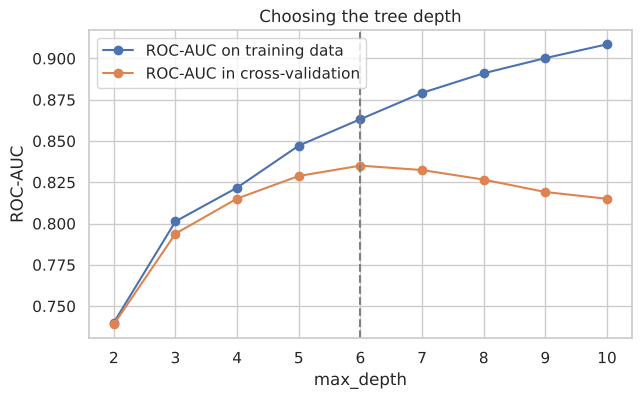

,ROC-AUC on training data,ROC-AUC in cross-validation
max_depth,,
2,0.740,0.739
3,0.801,0.794
4,0.822,0.815
5,0.847,0.829
6,0.863,0.835
7,0.879,0.832
8,0.891,0.827
9,0.900,0.819
10,0.909,0.815


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for depth in range(2, 11):
    pipe = Pipeline([("prep", tree_prep),
                     ("model", MyDecisionTree(max_depth=depth, min_samples_leaf=20))])
    cv_proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    pipe.fit(X_train, y_train)
    rows.append({"max_depth": depth,
                 "ROC-AUC on training data": roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                 "ROC-AUC in cross-validation": roc_auc_score(y_train, cv_proba)})

depth_table = pd.DataFrame(rows).set_index("max_depth")
best_depth = depth_table["ROC-AUC in cross-validation"].idxmax()

depth_table.plot(marker="o", figsize=(7, 4), title="Choosing the tree depth")
plt.axvline(best_depth, color="grey", linestyle="--")
plt.ylabel("ROC-AUC")
plt.show()

print("Best depth (cross-validation on train):", best_depth)
depth_table.round(3)

**Reading it:** on the training data the score keeps rising with depth (the tree memorises more and more). In cross-validation it rises until **depth 6** and then falls — that is **overfitting** happening in front of us. So we use `max_depth = 6`.

### 4.5 Put every model into a Pipeline

`raw data → preparation (encode, and scale for Logistic Regression) → our model`. Calling `.fit(X_train, y_train)` runs every step in order, learning **only from the training data**. `.predict(...)` later pushes new data through the same steps automatically.

The same `preprocessor` object is reused by Baseline and Logistic Regression. That is safe: each `fit` re-learns it from the same `X_train`. The tree uses `tree_prep` (no scaling).

In [ ]:
baseline = Pipeline([("prep", preprocessor), ("model", MyBaseline())])

log_reg = Pipeline([("prep", preprocessor),
                    ("model", MyLogisticRegression())])

tree = Pipeline([("prep", tree_prep),
                 ("model", MyDecisionTree(max_depth=best_depth, min_samples_leaf=20))])

### 4.6 Fit on the training data

`fit` is where the learning happens. Note that we pass **only `X_train` and `y_train`**: the test set is not touched.

In [ ]:
import time

for name, model in [("Baseline", baseline), ("Logistic Regression", log_reg), ("Decision Tree", tree)]:
    start = time.time()
    model.fit(X_train, y_train)
    print(f"{name:20s} trained in {time.time() - start:.2f} s")

Baseline             trained in 0.01 s
Logistic Regression  trained in 0.14 s
Decision Tree        trained in 5.93 s


### 4.7 What did Logistic Regression learn?

Each feature got a **coefficient**. The sign shows the direction and the size shows the strength. Because all numeric features were scaled to the same range, the sizes are comparable.

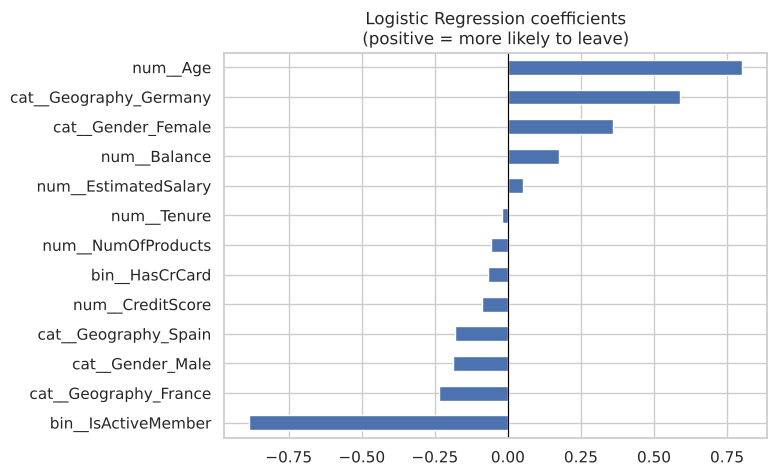

bin__IsActiveMember      -0.89
cat__Geography_France    -0.24
cat__Gender_Male         -0.19
cat__Geography_Spain     -0.18
num__CreditScore         -0.09
bin__HasCrCard           -0.07
num__NumOfProducts       -0.06
num__Tenure              -0.02
num__EstimatedSalary      0.05
num__Balance              0.18
cat__Gender_Female        0.36
cat__Geography_Germany    0.59
num__Age                  0.80
dtype: float64

In [ ]:
feature_names = log_reg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps["model"].w, index=feature_names).sort_values()

coefs.plot(kind="barh", figsize=(7, 5), title="Logistic Regression coefficients\n(positive = more likely to leave)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

coefs.round(2)

**How to read this:** bars to the right push the prediction towards *leaves*, bars to the left towards *stays*. `Age` (+0.80), `Geography_Germany` (+0.59) and `IsActiveMember` (−0.89) are the strongest.

Notice that `NumOfProducts` gets almost **zero** (−0.06), although the EDA showed it matters a lot. Logistic Regression has one weight per feature, so it can only say "more products → more risk" or "more products → less risk". The real pattern is a dip (27 % → 8 % → 83 % → 100 %), and the two directions cancel out. A tree can handle it by splitting customers into groups. This is why the Decision Tree is our main model.

### 4.8 What did the Decision Tree learn? Its first questions

We print the top three levels of the tree we grew.

In [ ]:
names = tree.named_steps["prep"].get_feature_names_out()

def show_tree(node, depth=0, max_show=3):
    pad = "    " * depth
    if "feature" not in node or depth == max_show:          # a leaf (or as deep as we print)
        print(f"{pad}-> P(leave) = {node['p_leave']:.2f}")
        return
    print(f"{pad}{names[node['feature']]} <= {node['threshold']:,.1f} ?")
    show_tree(node["left"], depth + 1, max_show)             # answer "yes"
    show_tree(node["right"], depth + 1, max_show)            # answer "no"

def count_leaves(node):
    if "feature" not in node:
        return 1
    return count_leaves(node["left"]) + count_leaves(node["right"])

my_tree = tree.named_steps["model"].tree_
show_tree(my_tree)
print("\nThe whole tree has", count_leaves(my_tree), "leaves.")

num__Age <= 42.5 ?
    num__NumOfProducts <= 2.5 ?
        num__NumOfProducts <= 1.5 ?
            -> P(leave) = 0.44
            -> P(leave) = 0.14
        num__Balance <= 55,948.9 ?
            -> P(leave) = 0.78
            -> P(leave) = 0.98
    bin__IsActiveMember <= 0.5 ?
        num__Age <= 47.5 ?
            -> P(leave) = 0.74
            -> P(leave) = 0.93
        num__Age <= 62.5 ?
            -> P(leave) = 0.65
            -> P(leave) = 0.24

The whole tree has 47 leaves.


Because the tree saw the numbers in real units, its questions read like a flowchart (the "white box" from the lecture). The first question is **"Age ≤ 42.5?"**:

- **Younger (≤ 42):** the next question is about products. With **2 products** the risk is low (0.14); with **3–4 products** it is very high (0.78–0.98).
- **Older (> 42):** the next question is **"inactive?"** (`IsActiveMember ≤ 0.5` means 0 = inactive). Inactive older customers are the most at risk (0.74–0.93); active ones are much safer, especially over 62 (0.24).

These are the same signals we found in the EDA, and the tree catches the "2 is safe, 3–4 is bad" dip that Logistic Regression missed. The full tree has 47 leaves.

(Here *P(leave)* is the weighted share of leavers in that node; because leavers get a bigger weight, it is higher than the raw share.)

We have not looked at the test set yet. Next, in section 5, we evaluate the models on it.

## 5. Evaluate on the test set

Now, for the first time, the models see the **test set** (2,000 customers they have never seen). We compute four metrics:

| Metric | Question it answers |
|---|---|
| **Accuracy** | Out of all customers, what share did we classify correctly? |
| **Precision** | Of the customers we *predicted would leave*, how many really left? |
| **Recall** | Of the customers who *really left*, how many did we catch? |
| **F1** | One number that balances precision and recall |
| **ROC-AUC** | If we pick one leaver and one stayer at random, how often does the model give the leaver the higher risk? (1 = perfect, 0.5 = coin flip) |

Remember: accuracy alone is misleading here, because ~80 % of customers stay.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {"Baseline (always 'stays')": baseline, "Logistic Regression": log_reg, "Decision Tree": tree}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
Baseline (always 'stays'),0.796,0.000,0.000,0.000,0.500
Logistic Regression,0.714,0.387,0.700,0.499,0.777
Decision Tree,0.762,0.451,0.784,0.572,0.842


### 5.1 Confusion matrix

The confusion matrix counts every type of right and wrong answer:

- **True negative (TN):** stays, predicted stays. ✅
- **True positive (TP):** left, predicted leaves. ✅ (we caught them)
- **False positive (FP):** stays, but predicted leaves. ❌ (a pointless call to a happy customer)
- **False negative (FN):** left, but predicted stays. ❌ (**the costly mistake**: a lost customer we did not notice)

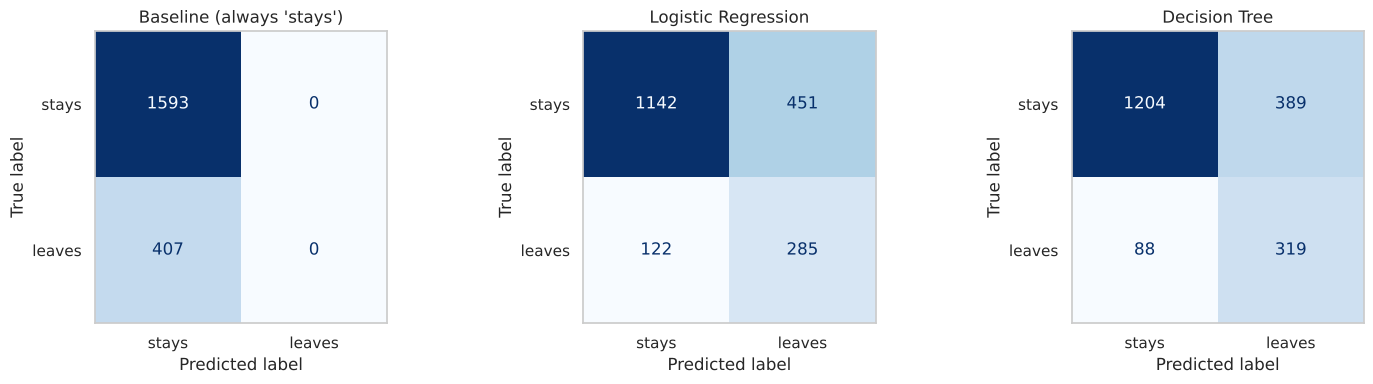

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["stays", "leaves"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name in ["Logistic Regression", "Decision Tree"]:
    print("=====", name, "=====")
    print(classification_report(y_test, models[name].predict(X_test), target_names=["stays", "leaves"]))

===== Logistic Regression =====
              precision    recall  f1-score   support

       stays       0.90      0.72      0.80      1593
      leaves       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

===== Decision Tree =====
              precision    recall  f1-score   support

       stays       0.93      0.76      0.83      1593
      leaves       0.45      0.78      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.77      0.70      2000
weighted avg       0.83      0.76      0.78      2000



### 5.2 Bonus: moving the decision threshold

A classifier does not really say "leaves" or "stays". It gives a **probability** of leaving, and the default rule is *"leaves if probability ≥ 0.5"*. We can change that cut-off (the **threshold**):

- **Lower threshold** → we flag more customers → higher **recall** (we catch more leavers) but lower **precision** (more false alarms).
- **Higher threshold** → we flag fewer customers → higher precision, lower recall.

Which is better depends on the bank's costs: a retention call is cheap, a lost customer is expensive.

In [ ]:
proba = tree.predict_proba(X_test)[:, 1]   # probability of leaving, for each test customer

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = proba >= t
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "customers flagged": int(pred.sum())})
pd.DataFrame(rows).set_index("threshold").round(3)

,precision,recall,F1,customers flagged
threshold,,,,
0.3,0.402,0.843,0.544,854
0.4,0.451,0.784,0.572,708
0.5,0.451,0.784,0.572,708
0.6,0.505,0.688,0.582,555
0.7,0.771,0.479,0.591,253


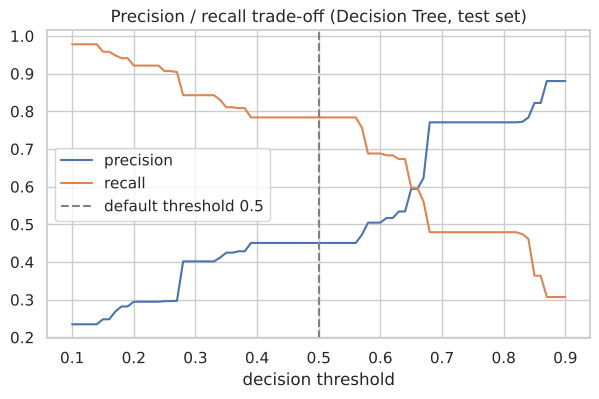

In [ ]:
ts = np.arange(0.1, 0.91, 0.01)
prec = [precision_score(y_test, proba >= t, zero_division=0) for t in ts]
rec = [recall_score(y_test, proba >= t) for t in ts]

plt.figure(figsize=(7, 4))
plt.plot(ts, prec, label="precision")
plt.plot(ts, rec, label="recall")
plt.axvline(0.5, color="grey", linestyle="--", label="default threshold 0.5")
plt.xlabel("decision threshold")
plt.title("Precision / recall trade-off (Decision Tree, test set)")
plt.legend()
plt.show()

**Choosing a threshold honestly.** If we picked the "best" threshold by looking at the test set, we would be tuning on the exam. Instead we choose it **using only the training data**: `cross_val_predict` gives every training customer a prediction from a model that did *not* see that customer, and we pick the threshold with the best F1 there. Then we apply it **once** to the test set.

In [ ]:
# same 5-fold split of the TRAINING data as in section 4.4
train_proba = cross_val_predict(tree, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

candidates = np.arange(0.3, 0.81, 0.01)
best_t = max(candidates, key=lambda t: f1_score(y_train, train_proba >= t))
print(f"Best threshold chosen on TRAIN (cross-validation): {best_t:.2f}")

pred_tuned = proba >= best_t
print("\nOn the test set with this threshold:")
print("precision:", round(precision_score(y_test, pred_tuned), 3))
print("recall:   ", round(recall_score(y_test, pred_tuned), 3))
print("F1:       ", round(f1_score(y_test, pred_tuned), 3))

Best threshold chosen on TRAIN (cross-validation): 0.66

On the test set with this threshold:
precision: 0.594
recall:    0.597
F1:        0.596


**Reading it:** our tree has only a few dozen leaves, so it can only output a few dozen different probabilities. That is why the precision/recall curve moves in **steps**, and why thresholds 0.4 and 0.5 give exactly the same result (no leaf has a probability between them).

With the tuned threshold (≈ 0.66) the model makes **far fewer false alarms** (precision 0.45 → 0.59) but misses more leavers (recall 0.78 → 0.60); F1 rises slightly (0.57 → 0.60). If the bank cares most about *not losing anyone*, it should go the other way and use a lower threshold such as 0.3 (recall ≈ 0.84, precision ≈ 0.40). There is no single "correct" threshold; it is a business decision.

### 5.3 Which features matter most? (permutation importance)

**Permutation importance** shuffles one column at a time on the test set and measures how much the model's quality (ROC-AUC) drops. A big drop means the model relied heavily on that column. It works on the *original* columns, so it is easier to read than one-hot columns.

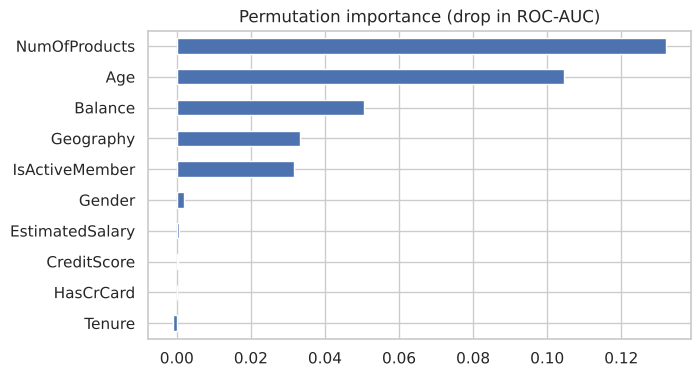

NumOfProducts      0.132
Age                0.105
Balance            0.051
Geography          0.033
IsActiveMember     0.032
Gender             0.002
EstimatedSalary    0.001
CreditScore        0.000
HasCrCard          0.000
Tenure            -0.001
dtype: float64

In [ ]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(tree, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(7, 4), title="Permutation importance (drop in ROC-AUC)")
plt.show()
importance.sort_values(ascending=False).round(3)

**Reading it:** `NumOfProducts` and `Age` are by far the most important, followed by `Balance`, `Geography` and `IsActiveMember`. `Gender`, `CreditScore`, `EstimatedSalary`, `HasCrCard` and `Tenure` are close to zero: shuffling them does not hurt the tree, so it barely uses them. This matches the EDA (churn rate was flat across tenure and card ownership).

Note the contrast with Logistic Regression: there `NumOfProducts` had a weight of almost zero, while for the tree it is the **most** important feature — because the tree can split on the "2 is safe, 3–4 is bad" pattern.

### 5.4 Bonus: feature engineering

We add three features built from existing columns, computed row by row (so there is no leakage):

- `ZeroBalance`: 1 if the account balance is 0 (a third of customers).
- `BalanceSalaryRatio`: balance relative to salary.
- `Age_x_Products`: age × number of products, a simple interaction.

Do they help? We compare on the same test set.

In [ ]:
def add_features(d):
    d = d.copy()
    d["ZeroBalance"] = (d["Balance"] == 0).astype(int)
    d["BalanceSalaryRatio"] = d["Balance"] / (d["EstimatedSalary"] + 1)
    d["Age_x_Products"] = d["Age"] * d["NumOfProducts"]
    return d

X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)

prep_fe = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols + ["BalanceSalaryRatio", "Age_x_Products"]),   # no scaling for a tree
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols + ["ZeroBalance"]),
])

tree_fe = Pipeline([
    ("prep", prep_fe),
    ("model", MyDecisionTree(max_depth=best_depth, min_samples_leaf=20)),
]).fit(X_train_fe, y_train)

pred_fe = tree_fe.predict(X_test_fe)
compare = pd.DataFrame({
    "Decision Tree": [roc_auc_score(y_test, proba), precision_score(y_test, tree.predict(X_test)),
                      recall_score(y_test, tree.predict(X_test)), f1_score(y_test, tree.predict(X_test))],
    "Decision Tree + new features": [roc_auc_score(y_test, tree_fe.predict_proba(X_test_fe)[:, 1]),
                                     precision_score(y_test, pred_fe), recall_score(y_test, pred_fe),
                                     f1_score(y_test, pred_fe)],
}, index=["ROC-AUC", "precision", "recall", "F1"]).round(3)
compare

,Decision Tree,Decision Tree + new features
ROC-AUC,0.842,0.843
precision,0.451,0.451
recall,0.784,0.786
F1,0.572,0.573


**Result:** the new features change almost nothing (ROC-AUC 0.842 → 0.843, F1 0.572 → 0.573). A decision tree can already combine age, products and balance on its own by asking several questions in a row, so the hand-made features add no real value. That is an honest negative result: not every idea helps, and we keep the simpler model.

### 5.5 An honest look at the failures

Which leavers does the model miss (false negatives at threshold 0.5)? We compare them with *all* leavers.

In [ ]:
pred_default = proba >= 0.5
missed = X_test[(y_test == 1) & (~pred_default)]
all_leavers = X_test[y_test == 1]

print("Leavers in test set:", len(all_leavers), "| missed by the model:", len(missed))
print("Share from Germany  -> missed:", round((missed["Geography"] == "Germany").mean(), 2),
      "| all leavers:", round((all_leavers["Geography"] == "Germany").mean(), 2))
pd.DataFrame({"missed leavers": missed[["Age", "NumOfProducts", "IsActiveMember", "Balance"]].mean(),
              "all leavers": all_leavers[["Age", "NumOfProducts", "IsActiveMember", "Balance"]].mean()}).round(2)

Leavers in test set: 407 | missed by the model: 88
Share from Germany  -> missed: 0.23 | all leavers: 0.37


,missed leavers,all leavers
Age,38.11,45.07
NumOfProducts,1.56,1.51
IsActiveMember,0.33,0.35
Balance,90716.28,90192.46


**Where it fails:** the tree misses 88 of the 407 leavers. They are **younger** (average age ≈ 38 vs ≈ 45 for all leavers) and **less often from Germany** (23 % vs 37 %). In other words, they look like typical loyal customers, and nothing in the data hints that they were about to leave. The dataset has no information about *why* people leave (complaints, better offers from competitors, life events), so some churn is simply unpredictable from these columns.

### 5.6 Is our code correct? A check against scikit-learn

We wrote the models ourselves, so we compare them with scikit-learn's ready-made versions trained with the same settings. This is **only a check** of our implementation; all the analysis above uses our own models.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# C=1e6 switches off sklearn's default penalty, because our version has no penalty (as in the lecture)
pairs = {
    "Logistic Regression": (log_reg, preprocessor,
                            LogisticRegression(class_weight="balanced", C=1e6, max_iter=1000)),
    "Decision Tree": (tree, tree_prep, DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20,
                                                   class_weight="balanced", random_state=0)),
}
rows = []
for name, (ours, prep, sk_model) in pairs.items():
    ref = Pipeline([("prep", prep), ("model", sk_model)]).fit(X_train, y_train)
    for who, m in [("ours", ours), ("sklearn", ref)]:
        rows.append({"model": name, "code": who,
                     "F1": f1_score(y_test, m.predict(X_test)),
                     "ROC-AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
pd.DataFrame(rows).set_index(["model", "code"]).round(3)

F1  ROC-AUC
model               code                   
Logistic Regression ours     0.499    0.777
                    sklearn  0.499    0.777
Decision Tree       ours     0.572    0.842
                    sklearn  0.572    0.842

Our Logistic Regression and Decision Tree give **the same numbers** as scikit-learn. So our code does what the textbook algorithms do.

## 6. Conclusion

**Question:** can we predict which bank customers will leave? **Answer: partly, yes.**

**All three models were written from scratch in NumPy** (Baseline, Logistic Regression with gradient descent, Decision Tree with Gini impurity), and section 5.6 shows they give the same results as scikit-learn.

**Results (test set, 2,000 customers, our Decision Tree, depth 6):**
- Accuracy ≈ 0.76, precision ≈ 0.45, recall ≈ 0.78, F1 ≈ 0.57, ROC-AUC ≈ 0.84.
- It clearly beats the baseline "everyone stays" (accuracy ≈ 0.80, but recall = 0: it finds nobody who leaves).
- The Decision Tree beat Logistic Regression (F1 0.57 vs 0.50, ROC-AUC 0.84 vs 0.78), because some relationships are not straight lines: customers with 2 products rarely leave, while those with 1 or 3-4 products leave often. A tree can split on that; a single weight cannot.

**What the model learned:** the strongest signals are **number of products** (2 is safe, 3-4 is a warning sign) and **age** (older customers, especially 50-60, leave much more), then **balance**, **Germany** and **inactive membership**. Tenure, salary, credit score and having a credit card hardly matter.

**Trade-off:** with the default threshold the tree catches about 4 of 5 leavers (recall 0.78), but more than half of the flagged customers would not have left (precision 0.45). A tuned threshold (≈ 0.66, chosen on the training data) gives fewer false alarms (precision ≈ 0.59) but catches only ≈ 60 % of leavers. The right choice depends on what a retention call costs compared to losing a customer.

**Where it fails:** it misses leavers who look like ordinary loyal customers (younger, less often from Germany). The data does not contain the reasons for leaving, so there is a ceiling on what any model can do here.

**Would I trust it?** As a tool to **prioritise** whom the bank should contact first, yes: it is much better than guessing, and its rules are easy to explain to a bank manager (e.g. "over 42 and inactive → high risk"). As a tool to make automatic decisions about individual customers, no: more than half of its "will leave" alerts are false and it misses about a fifth of real leavers.

**Limitations:**
- The data looks synthetic or simplified (36 % of customers have a zero balance, none of them in Germany; the Kaggle page says "U.S. bank" but the countries are France, Germany and Spain).
- One train/test split (2,000 test customers) gives results with some uncertainty; the numbers could move by a couple of percentage points with another split.
- A single tree is somewhat unstable: a small change in the training data can change its questions.
- The tree depth and the threshold were chosen with cross-validation on the training data only, and the test set was used once for the final numbers (no leakage).

## Sources

- Dataset: *Bank Customer Churn Prediction*, Shantanu Dhakad, Kaggle: https://www.kaggle.com/datasets/shantanudhakadd/bank-customer-churn-prediction
- Models: written by us from scratch in NumPy, following the course lectures: Week 5 *Classification* (logistic regression, sigmoid, gradient descent on log loss) and Week 7 *Decision Trees* (Gini impurity, information gain, CART `grow(node)`, stopping rules, validation curve on depth).
- Libraries: pandas, NumPy, matplotlib, seaborn; scikit-learn only for the split, preparation (`Pipeline`, `ColumnTransformer`, scaler, encoder), metrics, `cross_val_predict`, `permutation_importance` and the correctness check in 5.6.
- Method follows the course workflow (Weeks 1-6): split first, fit every preparation step on the training data only, evaluate once on the test set.